In [2]:
# Import the necessary libraries

import os
import json
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from pathlib import Path
from tqdm import tqdm
from transformers import BertTokenizer, BertModel
from sklearn.model_selection import KFold
from category_encoders import BinaryEncoder, OneHotEncoder, TargetEncoder
from sklearn.metrics import pairwise_distances
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn import cluster


In [3]:
print(f"Pandas: {pd.__version__}")
print(f"Numpy: {np.__version__}")
print(f"Seaborn: {sns.__version__}")
print(f"Transformers: {torch.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

Pandas: 2.1.3
Numpy: 1.26.0
Seaborn: 0.12.2
Transformers: 2.1.1+cpu
Scikit-learn: 1.3.2


In [4]:
# A class to load the data from the json files

class DataLoader:
    def __init__(self, data_path):
        self.data_path = data_path

    def load_data(self):
        data_list = []

        for file in os.listdir(self.data_path):
            if file.endswith('.json'):
                data = self._extract_data(os.path.join(self.data_path, file))
                if all(value != '' for value in data.values()):
                    data_list.append(data)

        return pd.DataFrame(data_list)

    def _extract_data(self, file_path):
        with open(file_path, 'r', encoding='utf-8') as file:
            data = json.load(file)

        protocol = data.get('protocolSection', {})
        identification = protocol.get('identificationModule', {})
        description = protocol.get('descriptionModule', {})
        conditions = protocol.get('conditionsModule', {})
        design = protocol.get('designModule', {})
        eligibility = protocol.get('eligibilityModule', {})

        primary_purpose = design.get('designInfo', {}).get('primaryPurpose', '')


        extracted_data = {
            "NCT ID": self._try_except(identification, 'nctId'),
            "Study Type": self._try_except(design, 'studyType'),
            "Standard Ages": self._try_except(eligibility, 'stdAges', join=True),
            "Conditions": self._try_except(conditions, 'conditions', join=True),
            "Eligibility Criteria": self._try_except(eligibility, 'eligibilityCriteria'),
            "Sex": self._try_except(eligibility, 'sex')
        }

        return extracted_data

    def _try_except(self, data_dict, field_name, join=False):
        try:
            value = data_dict.get(field_name, '')
            if join and isinstance(value, list):
                return ", ".join(value)
            return value
        except Exception as e:
            print(f"Error extracting {field_name}: {str(e)}")
            return ''

In [7]:
def extract_raw_data(input_dir=None, output_file=None):
    '''
    Extracts raw data from the json files and saves it to a csv file.

    Parameters:
    - input_dir (str): The directory containing the input JSON files.
    - output_file (str): The name of the CSV file to save the raw data.

    Returns:
    None
    '''
    if input_dir is None or output_file is None:
        raise ValueError("Both 'input_dir' and 'output_file' must be specified.")

    # Assuming DataLoader is a class that loads data from JSON files
    dataloader = DataLoader(input_dir)
    raw_data = dataloader.load_data()

    # Save raw data to CSV
    raw_data.to_csv(output_file, index=False)

    print(f"Raw data extracted to {output_file}")


In [8]:
input_dir = Path(r'.\data\ctg-studies.json')
output_file = Path(r'.\data\ctg-studies.csv')

extract_raw_data(input_dir=input_dir, output_file=output_file)

Raw data extracted to data\ctg-studies.csv


In [9]:
raw_data = pd.read_csv(r'.\data\ctg-studies.csv')
raw_data.isna().sum()

NCT ID                  0
Study Type              0
Standard Ages           0
Conditions              0
Eligibility Criteria    0
Sex                     0
dtype: int64

In [10]:
raw_data.describe()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
count,1266,1266,1266,1266,1266,1266
unique,1266,3,6,862,1254,3
top,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Multiple Myeloma,"Inclusion Criteria:\n\n1. Age ≥18 years old, m...",ALL
freq,1,1198,836,78,3,1239


In [11]:
raw_data.head()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
0,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Ovarian Cancer,DISEASE CHARACTERISTICS:\n\n* Histologically p...,FEMALE
1,NCT00085930,INTERVENTIONAL,"CHILD, ADULT",Neuroblastoma,Inclusion Criteria:\n\nHigh risk neuroblastoma...,ALL
2,NCT00881920,INTERVENTIONAL,"ADULT, OLDER_ADULT","Lymphoma, Myeloma, Leukemia",INCLUSION CRITERIA:\n\nBLOOD PROCUREMENT:\n\n*...,ALL
3,NCT00902044,INTERVENTIONAL,"CHILD, ADULT, OLDER_ADULT",Sarcoma,INCLUSION CRITERIA:\n\nProcurement Eligibility...,ALL
4,NCT00924326,INTERVENTIONAL,"ADULT, OLDER_ADULT","Primary Mediastinal B-cell Lymphoma, Diffuse, ...",* INCLUSION CRITERIA:\n\n 1. Patient must hav...,ALL


In [12]:
raw_data['Study Type'].value_counts()

Study Type
INTERVENTIONAL     1198
OBSERVATIONAL        63
EXPANDED_ACCESS       5
Name: count, dtype: int64

In [13]:
raw_data['Standard Ages'].value_counts()

Standard Ages
ADULT, OLDER_ADULT           836
CHILD, ADULT, OLDER_ADULT    316
CHILD, ADULT                  97
ADULT                          9
CHILD                          7
OLDER_ADULT                    1
Name: count, dtype: int64

In [14]:
raw_data['Sex'].value_counts()

Sex
ALL       1239
FEMALE      15
MALE        12
Name: count, dtype: int64

In [15]:
def extract_eligibility_features(data=None, bert_model=None, tokenizer=None):
    '''
    Extracts features from the eligibility criteria using the BERT model.

    Parameters:
    - data (pd.DataFrame): The data containing the eligibility criteria.
    - bert_model (str): The name of the BERT model to use.
    - tokenizer (str): The name of the tokenizer to use.

    Returns:
    pd.DataFrame: The data with the extracted features.
    '''
    if data is None or bert_model is None or tokenizer is None:
        raise ValueError("All parameters must be specified.")

    # Load the BERT model and tokenizer
    bert_model = BertModel.from_pretrained(bert_model)
    tokenizer = BertTokenizer.from_pretrained(tokenizer)

    # Extract features from the eligibility criteria
    features = []
    for criteria in tqdm(data['Eligibility Criteria']):
        inputs = tokenizer(criteria, return_tensors='pt', truncation=True, max_length=512)
        outputs = bert_model(**inputs)
        features.append(outputs.pooler_output.detach().numpy())

    features = [feature.flatten() for feature in features]
    # Add the extracted features to the data
    features = pd.DataFrame(features)
    features.columns = [f"feature_{i}" for i in range(features.shape[1])]

    return features

In [16]:
def extract_features(data=None, bert_model=None, tokenizer=None, encoder=BinaryEncoder):
    '''
    Extracts features from the raw data using the BERT model and the specified encoder.

    Parameters:
    - data (pd.DataFrame): The raw data to extract features from.
    - bert_model (transformers.BertModel): The BERT model to use for feature extraction.
    - tokenizer (transformers.BertTokenizer): The tokenizer to use for tokenizing the input text.
    - encoder (category_encoders.Encoder): The encoder to use for encoding categorical features.

    Returns:
    pd.DataFrame: The extracted nct_id, features.
    '''
    if data is None or bert_model is None or tokenizer is None:
        raise ValueError("All arguments must be specified.")

    # Extract features from eligibility criteria using BERT
    criteria_features = extract_eligibility_features(data, bert_model, tokenizer)
    
    # Extract features from other fields using the specified encoder
    nominal_features = data.drop(columns=['Eligibility Criteria', 'NCT ID', 'Conditions'])
    
    encoder = encoder(cols=nominal_features.columns.tolist())
    other_features = encoder.fit_transform(nominal_features)

    # Combine the extracted features
    features = pd.concat([data['NCT ID'] ,criteria_features, other_features], axis=1)
    
    return features


In [17]:
blue_bert = "bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16"
biomed_bert = 'microsoft/BiomedNLP-BiomedBERT-large-uncased-abstract'


In [18]:
feature_matrix = extract_features(data=raw_data, bert_model=biomed_bert, tokenizer=biomed_bert, encoder=BinaryEncoder)

KeyboardInterrupt: 

In [ ]:
feature_matrix.to_csv(Path(r'./data/feature_matrix/feature_matrix_biomedbert.csv'), index=False)

NameError: name 'feature_matrix' is not defined

In [19]:
feature_matrix_biomedbert = pd.read_csv(Path(r'./data/feature_matrix/feature_matrix_biomedbert.csv'))
feature_matrix_bluebert = pd.read_csv(Path(r'./data/feature_matrix/feature_matrix_bluebert.csv'))
feature_matrix_biobert = pd.read_csv(Path(r'./data/feature_matrix/feature_matrix_biobert.csv'))

In [20]:
datasets = [feature_matrix_biomedbert, feature_matrix_bluebert, feature_matrix_biobert]

In [23]:
clusterers = [
    (
        'KMeans', 
        cluster.KMeans, 
        {
            'init': 'k-means++', 
            'n_init': 1, 
            'random_state': 42, 
            'copy_x': True, 
            'algorithm': 'elkan',
        },
    ),
    (
        'Spectral Clustering', 
        cluster.SpectralClustering, 
        {
            'eigen_solver': None, 
            'n_components': None, 
            'random_state': None, 
            'n_init': 10, 
            'gamma': 1.0, 
            'affinity': 'rbf', 
            'n_neighbors': 10, 
            'eigen_tol': 0.0, 
            'assign_labels': 'kmeans', 
            'degree': 3, 
            'coef0': 1, 
            'kernel_params': None, 
            'n_jobs': None
        },
    ),
    (
        'Affinity Propagation', 
        cluster.AffinityPropagation, 
        {
            'max_iter': 50000,
            'convergence_iter': 2000,
            'copy': True,
            'verbose': True,
            'random_state': None,
            'affinity': 'euclidean',
            'damping': 0.5,
            'preference': -7500
        },
    ),
    (
        'DBSCAN', 
        cluster.DBSCAN, 
        {
            'eps': 0.5, 
            'min_samples': 5, 
            'metric': 'euclidean', 
            'metric_params': None, 
            'algorithm': 'auto', 
            'leaf_size': 30, 
            'p': None, 
            'n_jobs': None
        },
    ),
    (
        'HDBSCAN',
        cluster.HDBSCAN,
        {
            'min_cluster_size': 5,
            'min_samples': None,
            'alpha': 1.0,
            'metric': 'euclidean',
            'p': None,
            'algorithm': 'best',
            'leaf_size': 40,
            'approx_min_span_tree': True,
            'gen_min_span_tree': False,
            'core_dist_n_jobs': 4,
            'cluster_selection_method': 'eom',
            'allow_single_cluster': False,
            'prediction_data': False
        }
    ),
    (
        'OPTICS', 
        cluster.OPTICS,
        {
            'min_samples': 5, 
            'max_eps': np.inf, 
            'metric': 'minkowski', 
            'p': 2, 
            'metric_params': None, 
            'cluster_method': 'xi', 
            'eps': None, 
            'xi': 0.05, 
            'min_cluster_size': None, 
            'algorithm': 'auto', 
            'leaf_size': 30, 
            'n_jobs': None
        },
    ), 
    (
        'BIRCH',
        cluster.Birch,
        {
            'threshold': 0.5,
            'branching_factor': 50,
            'n_clusters': 4,
            'compute_labels': True,
            'copy': True
        }
    )
]

In [24]:
clusterers = [
    (
        'KMeans',
        cluster.KMeans
    ),
    (
        'Spectral Clustering',
        cluster.SpectralClustering
    ),
    (
        'Affinity Propagation',
        cluster.AffinityPropagation
    ),
    (
        'DBSCAN',
        cluster.DBSCAN
    ),
    (
        'HDBSCAN',
        cluster.HDBSCAN
    ),
    (
        'OPTICS',
        cluster.OPTICS
    ),
    (
        'BIRCH',
        cluster.Birch
    )
]

In [27]:
def get_clusterer(clusterers, identifier):
    for clusterer_tuple in clusterers:
        if clusterer_tuple[0] == identifier:
            return clusterer_tuple
    return None  # Return None if no match is found

In [34]:
def crossval(model, model_params, X, num=None, number_of_clusters_required=False):

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    silhouette_scores = []
    calinski_harabasz_scores = []
    
    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]

        # Fit the model on the training data
        if number_of_clusters_required:
            clusterer = model(**model_params, n_clusters=num)
        else:
            clusterer = model(**model_params)

        clusterer.fit(X_train)

        # Predict on the test data
        labels = clusterer.predict(X_test)

        # Calculate silhouette score
        sil_score = silhouette_score(X_test, labels, metric='euclidean')
        cal_score = calinski_harabasz_score(X_test, labels)

        # Append results to the lists
        silhouette_scores.append(sil_score)
        calinski_harabasz_scores.append(cal_score)

    return silhouette_scores, calinski_harabasz_scores

In [40]:
print(crossval(cluster.KMeans, {'init': 'k-means++', 'n_init': 1, 'random_state': 42, 'copy_x': True, 'algorithm': 'elkan'}, feature_matrix_biomedbert.drop(columns=['NCT ID']), 4, True))

([0.17421250076323092, 0.16062830857580937, 0.1625447099872444, 0.16240784757677076, 0.15030191589147565], [113.21232856660235, 80.19990736747305, 89.15631168862943, 114.12110502988087, 101.884144525815])


In [43]:

def train_model(algorithm=None, model_params=None, dataset=None, number_of_clusters_required=False, clusterers=None):
    X = dataset.drop(columns=['NCT ID'])
    model_name, model = get_clusterer(clusterers=clusterers, identifier=algorithm)
    
    if number_of_clusters_required:

        average_silhouette_scores = []
        average_calinski_harabasz_scores = []
        number_of_clusters = range(2, 11)

        for num in number_of_clusters:

            silhouette_scores, calinski_harabasz_scores = crossval(model, model_params, X, num, number_of_clusters_required=True)
            mean_silhouette_score = np.mean(silhouette_scores)
            mean_calinski_harabasz_score = np.mean(calinski_harabasz_scores)

            average_silhouette_scores.append(mean_silhouette_score)
            average_calinski_harabasz_scores.append(mean_calinski_harabasz_score)

        print(f"{algorithm}")
        # print(f"Silhouette Scores: {average_silhouette_scores}")
        # print(f"Calinski-Harabasz Scores: {average_calinski_harabasz_scores}")
        
        # Plot the silhouette scores and Calinski-Harabasz scores in different subplot
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
        fig.suptitle('Silhouette Score and Calinski-Harabasz Score vs Number of Clusters', fontsize=16)
        ax1.plot(number_of_clusters, average_silhouette_scores)
        ax1.set_xlabel('Number of Clusters')
        ax1.set_ylabel('Silhouette Score')
        ax2.plot(number_of_clusters, average_calinski_harabasz_scores)
        ax2.set_xlabel('Number of Clusters')
        ax2.set_ylabel('Calinski-Harabasz Score')
        plt.show()

    else:
        silhouette_scores, calinski_harabasz_scores = crossval(model, model_params, X)
        print(f"Silhouette Scores: {silhouette_scores}")
        print(f"Calinski-Harabasz Scores: {calinski_harabasz_scores}")

# K-Means
## Dataset - Bluebert

KMeans


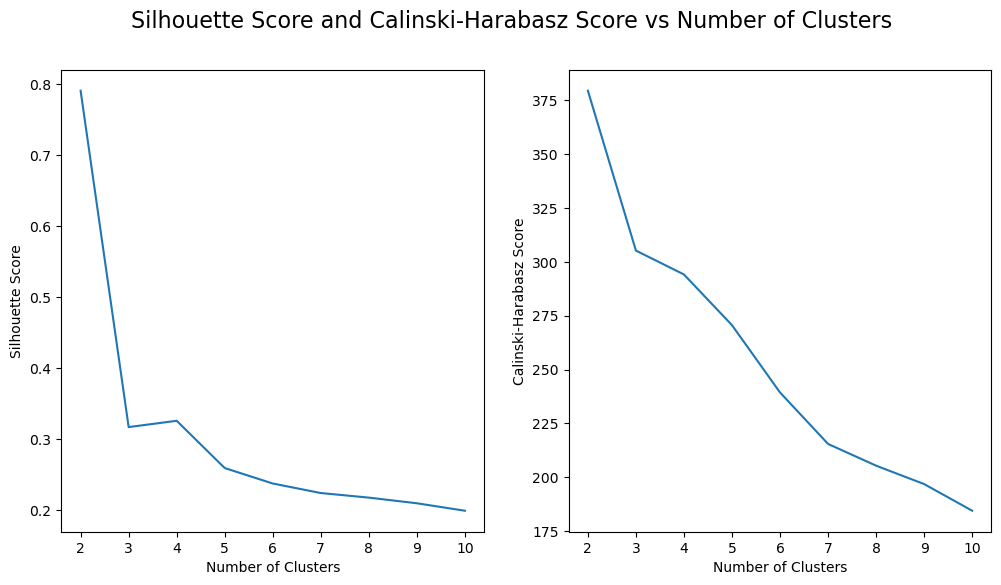

In [44]:
model_params = {
    'init': 'k-means++', 
    'n_init': 1, 
    'random_state': 42, 
    'copy_x': True, 
    'algorithm': 'elkan',
}
train_model(algorithm='KMeans', \
            model_params=model_params, \
            dataset=feature_matrix_bluebert, \
            number_of_clusters_required=True, \
            clusterers=clusterers)

# K-Means
## Dataset - Biomedbert

In [ ]:
model_params = {
    'init': 'k-means++', 
    'n_init': 1, 
    'random_state': 42, 
    'copy_x': True, 
    'algorithm': 'elkan',
}
train_model(algorithm='KMeans', \
            model_params=model_params, \
            dataset=feature_matrix_bluebert, \
            number_of_clusters_required=True, \
            clusterers=clusterers)

# Affinity Propogation

In [24]:
train_model(algorithm='Affinity Propagation', datasets=datasets, clusterers=clusterers)

{'max_iter': 50000, 'convergence_iter': 2000, 'copy': True, 'verbose': True, 'random_state': None, 'affinity': 'euclidean', 'damping': 0.5, 'preference': -7500}


Converged after 5226 iterations.


ValueError: Number of labels is 1. Valid values are 2 to n_samples - 1 (inclusive)